# 3 · Read the classifier results

**Question:** What was selected, how well did it generalize, and how uncertain is the comparison?

For readers familiar with validation and macro-F1. We inspect all 16 recipes,
then the five-seed comparison, validation curves, per-class outcomes and a
patient/seed bootstrap. These are **saved experimental results**, not new fits.

The compact patient confusion matrices let us recompute the primary interval
without downloading checkpoints. Their derivation and source hashes are recorded
in [data/provenance.json](data/provenance.json).

**Route:** screen → selected checkpoints → per-class outcomes → paired uncertainty.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'fedecg/models.py').is_file())
sys.path.insert(0, str(ROOT))
from notebooks._support import CLASSES, COLORS, NAMES, read_table, read_json, setup, finish
setup()
%matplotlib inline

## Read validation and test scores in the same recipe order

Each screen recipe uses seeds 11, 22 and 33. A run retains its highest validation
macro-F1 checkpoint; recipes are ranked by the mean of those three validation
scores. The selected recipe is MLP + RR with balanced cross-entropy.

Candidate families were expanded during development and the test set had
already been inspected. This is an exploratory comparison. A high test bar
does not make a recipe a newly validated winner.

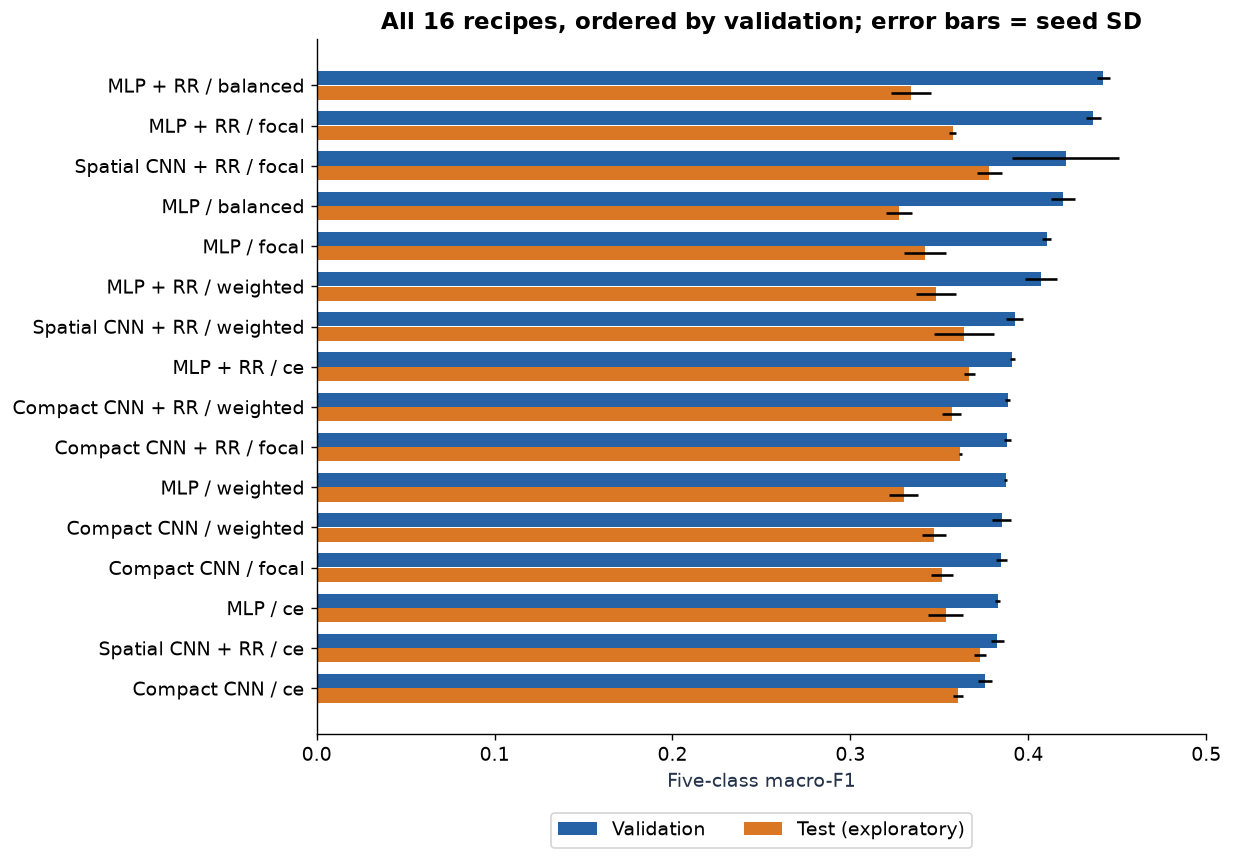

In [2]:
screen = read_table('complete_screen_common_seeds.csv').sort_values('validation_rank')
assert len(screen) == 16 and screen.iloc[0]['model'] == 'mlp_rr'
labels = [f"{NAMES[r.model]} / {r.loss}" for r in screen.itertuples()]
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(screen))
ax.barh(y - .18, screen.val_mean, .35, xerr=screen.val_sd, label='Validation', color=COLORS[0])
ax.barh(y + .18, screen.test_mean, .35, xerr=screen.test_sd, label='Test (exploratory)', color=COLORS[1])
ax.set(yticks=y, yticklabels=labels, xlabel='Five-class macro-F1',
       title='All 16 recipes, ordered by validation; error bars = seed SD', xlim=(0, .5))
ax.invert_yaxis(); ax.legend(loc='upper center', bbox_to_anchor=(.5, -.1), ncol=2)
finish(fig)

## Five seeds for the baseline and selected recipe

Only these two recipes were extended to seeds 44 and 55. Keep their five-seed
comparison separate from the three-seed screen above. Lines connect the same
training seed across recipes; they are useful for reading paired differences.

,Mean macro-F1,Seed SD,Seeds
Recipe,,,
MLP / CE,0.3545,0.0075,5
MLP + RR / balanced,0.3377,0.0123,5


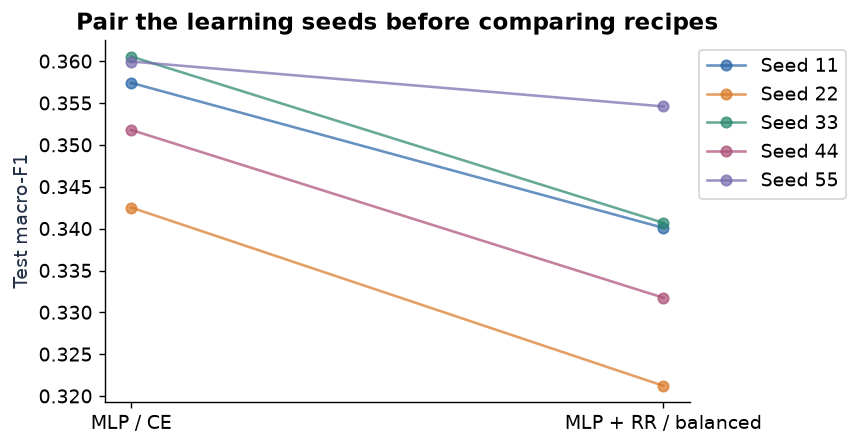

In [3]:
runs = read_table('run_summary.csv')
stems = ['main_mlp_ce', 'main_mlp_rr_balanced']
groups = [runs[runs.run.str.fullmatch(stem + r'_s\d+')].sort_values('seed') for stem in stems]
assert all(g.seed.tolist() == [11, 22, 33, 44, 55] for g in groups)
scores = np.stack([g.best_macro_f1.to_numpy() for g in groups])
display(pd.DataFrame({'Recipe': ['MLP / CE', 'MLP + RR / balanced'],
                      'Mean macro-F1': scores.mean(axis=1), 'Seed SD': scores.std(axis=1, ddof=1),
                      'Seeds': [5, 5]}).set_index('Recipe'))
fig, ax = plt.subplots(figsize=(7, 3.7))
for i, seed in enumerate(groups[0].seed):
    ax.plot([0, 1], scores[:, i], 'o-', alpha=.7, label=f'Seed {seed}')
ax.set(xticks=[0, 1], xticklabels=['MLP / CE', 'MLP + RR / balanced'],
       ylabel='Test macro-F1', title='Pair the learning seeds before comparing recipes')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
finish(fig)

## Checkpoints are selected using validation curves

The shaded range below is the minimum to maximum across five seeds, not a
confidence interval. The test set does not enter the checkpoint-selection rule.
Earlier exploratory test inspection still limits the study as a whole.

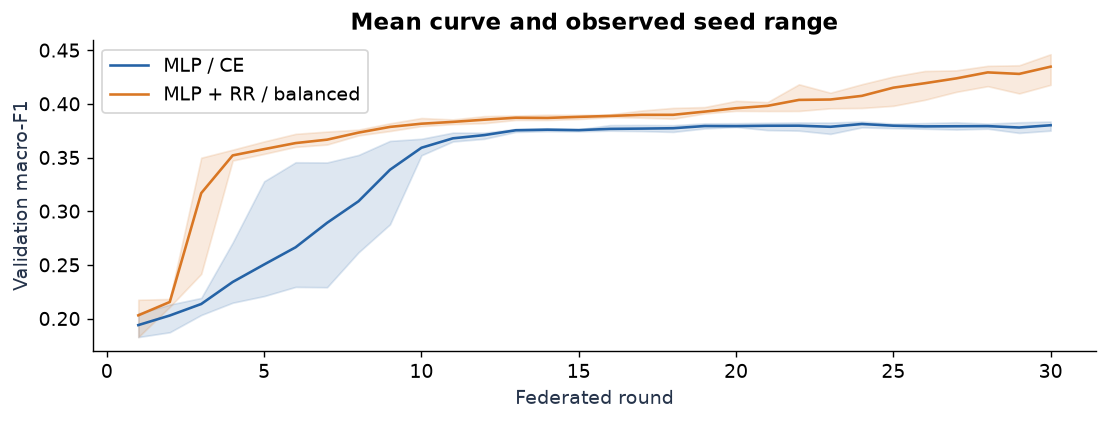

In [4]:
curves = pd.read_csv(ROOT / 'notebooks/data/validation_curves.csv')
fig, ax = plt.subplots(figsize=(9, 3.5))
for stem, label, color in zip(stems, ['MLP / CE', 'MLP + RR / balanced'], COLORS):
    values = curves.query('method == @stem').pivot(index='round', columns='seed', values='val_macro_f1')
    ax.plot(values.index, values.mean(axis=1), label=label, color=color)
    ax.fill_between(values.index, values.min(axis=1), values.max(axis=1), color=color, alpha=.15)
ax.set(xlabel='Federated round', ylabel='Validation macro-F1', title='Mean curve and observed seed range')
ax.legend(); finish(fig)

## Look inside the aggregate score

The following recalls average the five selected-checkpoint runs. The normalized
confusion matrix pools the five fitted seeds for visualization; it represents
repeated predictions on the same test patients. It does not multiply the number
of independent patients by five.

,MLP / CE recall,MLP + RR / balanced recall
N,0.9837,0.9356
S,0.0000,0.0444
V,0.8442,0.9211
F,0.0000,0.0010
Q,0.0000,0.0000


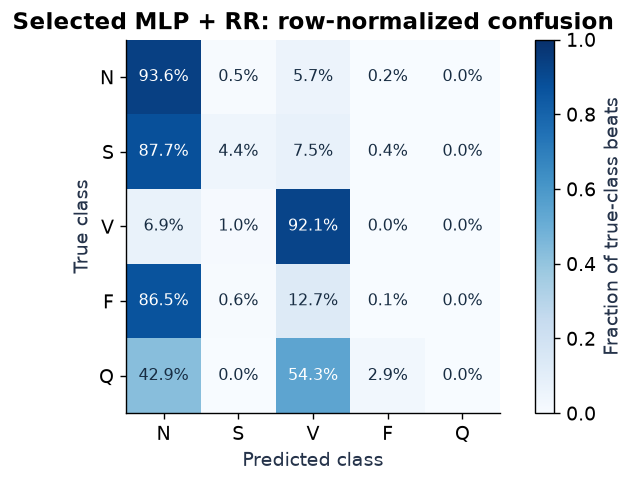

In [5]:
z = np.load(ROOT / 'notebooks/data/primary_patient_confusions.npz', allow_pickle=False)
cms = z['confusions']  # method × seed × patient × true class × predicted class
assert cms.shape == (2, 5, 22, 5, 5)
pooled = cms.sum(axis=2)
tp = np.diagonal(pooled, axis1=-2, axis2=-1)
recall = np.divide(tp, pooled.sum(axis=-1), out=np.zeros_like(tp, dtype=float), where=pooled.sum(axis=-1) > 0)
display(pd.DataFrame(recall.mean(axis=1).T, index=CLASSES,
                     columns=['MLP / CE recall', 'MLP + RR / balanced recall']))
cm = pooled[1].sum(axis=0)
norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(norm, vmin=0, vmax=1, cmap='Blues')
for i in range(5):
    for j in range(5):
        ax.text(j, i, f'{100 * norm[i, j]:.1f}%', ha='center', va='center',
                color='white' if norm[i, j] > .5 else '#182d43', fontsize=9)
ax.set(xticks=range(5), xticklabels=CLASSES, yticks=range(5), yticklabels=CLASSES,
       xlabel='Predicted class', ylabel='True class', title='Selected MLP + RR: row-normalized confusion')
fig.colorbar(im, ax=ax, label='Fraction of true-class beats'); finish(fig)

## Recompute the patient/seed interval in a few lines

1. Sample five learning seeds with replacement.
2. Sample 22 test patients with replacement, sharing the draws across methods.
3. Pool patient confusion counts **before** calculating fixed-five-class F1.
4. Average over sampled seeds and subtract baseline from selected recipe.

This preserves the pairing and patient clusters. We repeat it 5,000 times with
the recorded random seed. The interval conditions on fitted models and explored
recipes; it does not repeat model selection or resample training patients.

In [6]:
def macro_f1(confusion):
    diagonal = np.diagonal(confusion, axis1=-2, axis2=-1)
    denominator = confusion.sum(axis=-2) + confusion.sum(axis=-1)
    return np.divide(2 * diagonal, denominator, out=np.zeros_like(diagonal, dtype=float),
                     where=denominator > 0).mean(axis=-1)

np.testing.assert_allclose(macro_f1(cms.sum(axis=2)), scores, rtol=0, atol=1e-15)
rng = np.random.default_rng(20261028)
effects = []
for _ in range(5000):
    seed_ids = rng.integers(0, 5, 5)
    patient_ids = rng.integers(0, 22, 22)
    sampled = cms[:, seed_ids][:, :, patient_ids].sum(axis=2)
    averaged = macro_f1(sampled).mean(axis=1)
    effects.append(averaged[1] - averaged[0])
interval = np.quantile(effects, [.025, .975])
observed = float((scores[1] - scores[0]).mean())
reference = read_json('primary_uncertainty.json')
np.testing.assert_allclose(interval, reference['hierarchical_bootstrap_95ci'], rtol=0, atol=1e-14)
assert np.isclose(observed, reference['observed_macro_f1_difference'])
display(pd.DataFrame({'Selected minus baseline': [observed], '95% lower': [interval[0]], '95% upper': [interval[1]]}))

,Selected minus baseline,95% lower,95% upper
0,-0.0168,-0.0477,0.0319


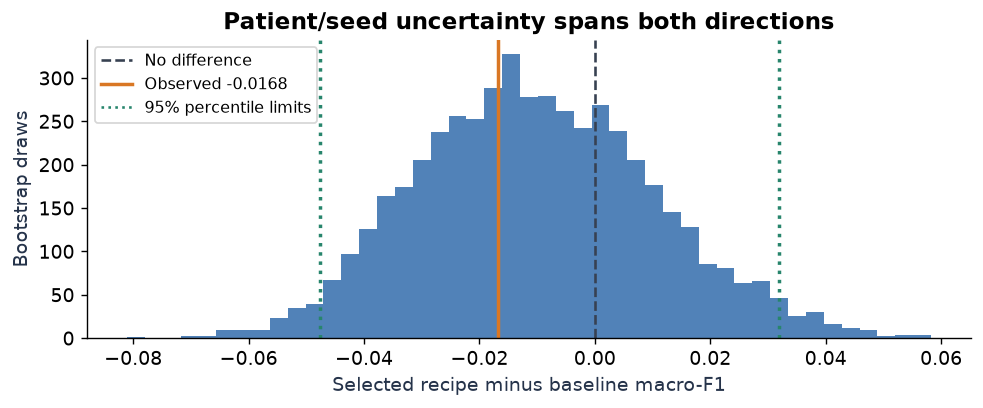

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(effects, bins=45, color=COLORS[0], alpha=.8)
ax.axvline(0, color='#374151', ls='--', label='No difference')
ax.axvline(observed, color=COLORS[1], lw=2, label=f'Observed {observed:+.4f}')
for edge in interval:
    ax.axvline(edge, color=COLORS[2], ls=':', lw=2)
ax.plot([], [], color=COLORS[2], ls=':', label='95% percentile limits')
ax.set(xlabel='Selected recipe minus baseline macro-F1', ylabel='Bootstrap draws',
       title='Patient/seed uncertainty spans both directions')
ax.legend(fontsize=9); finish(fig)

### Try it: identify the test leader and the validation choice

Find the highest test mean in the 16-recipe screen. Is it also the validation
choice? The answer below illustrates why the selection rule must be explicit.

In [8]:
display(screen.loc[[screen.val_mean.idxmax(), screen.test_mean.idxmax()],
                   ['validation_rank', 'model', 'loss', 'val_mean', 'test_mean']])
# A post-hoc test leader is exploratory; choosing it now needs fresh confirmation.

,validation_rank,model,loss,val_mean,test_mean
0,1,mlp_rr,balanced,0.4421,0.3340
2,3,cnn_spatial_rr,focal,0.4212,0.3781


**What the results support:** the selected recipe has a lower observed test
macro-F1 than the baseline, and the patient/seed interval spans zero. Rare-class
recall remains weak. This comparison does not establish a reliable predictive gain.

**Optional extension:** use `cms` to compare pooling confusion counts first
with averaging patient F1 first. They answer different questions because F1 is nonlinear.

**Next:** [4 · Experimental controls](04_experimental_controls.ipynb)